# Entrenamiento del modelo de regresión
**Workshop 3 · Parte A · Paso 4.** Objetivo: predecir `happiness_score` con las 6 features del contrato y serializar **preprocesamiento + modelo** en un único `Pipeline` (`models/model.pkl`).

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, joblib, sklearn, matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from src import cleaning as cl
df = pd.read_csv(ROOT / 'data' / 'processed' / 'happiness_clean.csv')
X, y, groups = df[cl.FEATURES], df[cl.TARGET], df['country']
print(X.shape, 'features:', cl.FEATURES)

(782, 6) features: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


## 1. Split 70 / 30 sin fuga entre años
Cada país aparece hasta 5 veces (una por año) y su puntaje cambia poco. Un split aleatorio por fila puede poner el mismo país en entrenamiento y en prueba, lo que **puede inflar** la métrica por fuga entre observaciones casi idénticas. Para evitar ese riesgo de diseño se usa `GroupShuffleSplit` agrupando por `country`: un país queda completo en train **o** en test. Más abajo se compara con el split aleatorio: con un modelo lineal de solo 6 variables la diferencia es pequeña y, en esta semilla, incluso va en sentido contrario (ruido de un único split), así que la decisión se toma por rigor metodológico y no por una mejora de la métrica.

In [2]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr, te = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te]))
print(f'train={len(X_tr)} ({len(X_tr)/len(X):.0%})  test={len(X_te)} ({len(X_te)/len(X):.0%})  países train={groups.iloc[tr].nunique()} test={groups.iloc[te].nunique()}')

train=542 (69%)  test=240 (31%)  países train=114 test=50


## 2. Modelos candidatos (todos dentro de un `Pipeline` con `StandardScaler`)

In [3]:
def metrics(m, Xa, ya):
    p = m.predict(Xa)
    return {'MAE': mean_absolute_error(ya, p), 'RMSE': np.sqrt(mean_squared_error(ya, p)), 'R2': r2_score(ya, p)}

candidatos = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
}
res, pipes = [], {}
for nombre, est in candidatos.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', est)]).fit(X_tr, y_tr)
    pipes[nombre] = pipe
    for split, (Xa, ya) in {'train': (X_tr, y_tr), 'test': (X_te, y_te)}.items():
        res.append({'modelo': nombre, 'conjunto': split, **metrics(pipe, Xa, ya)})
resultados = pd.DataFrame(res).round(4)
resultados

,modelo,conjunto,MAE,RMSE,R2
0,LinearRegression,train,0.4278,0.5428,0.7513
1,LinearRegression,test,0.4320,0.5620,0.7837
2,RandomForest,train,0.1899,0.2417,0.9507
3,RandomForest,test,0.4800,0.6106,0.7447


In [4]:
# Referencia: split aleatorio por filas (el mismo país puede caer en train y test) — solo comparación, una sola semilla
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.30, random_state=42)
ref = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]).fit(Xa, ya)
print('LinearRegression, split aleatorio por filas -> R2 test =', round(r2_score(yb, ref.predict(Xb)), 4))
print('LinearRegression, split por país            -> R2 test =', resultados.query("modelo=='LinearRegression' and conjunto=='test'")['R2'].iloc[0])

LinearRegression, split aleatorio por filas -> R2 test = 0.7595
LinearRegression, split por país            -> R2 test = 0.7837


## 3. Selección
Criterio: menor RMSE en test, y a igual desempeño se prefiere el modelo más simple e interpretable (el taller no busca optimizar la precisión).

In [5]:
test = resultados[resultados.conjunto == 'test'].set_index('modelo')
print(test)
mejor = test['RMSE'].idxmin()
dif = test['RMSE'].max() - test['RMSE'].min()
if dif < 0.02: mejor = 'LinearRegression'   # empate práctico -> modelo más simple
print('\nModelo elegido:', mejor)
modelo = pipes[mejor]

                 conjunto    MAE    RMSE      R2
modelo                                          
LinearRegression     test  0.432  0.5620  0.7837
RandomForest         test  0.480  0.6106  0.7447

Modelo elegido: LinearRegression


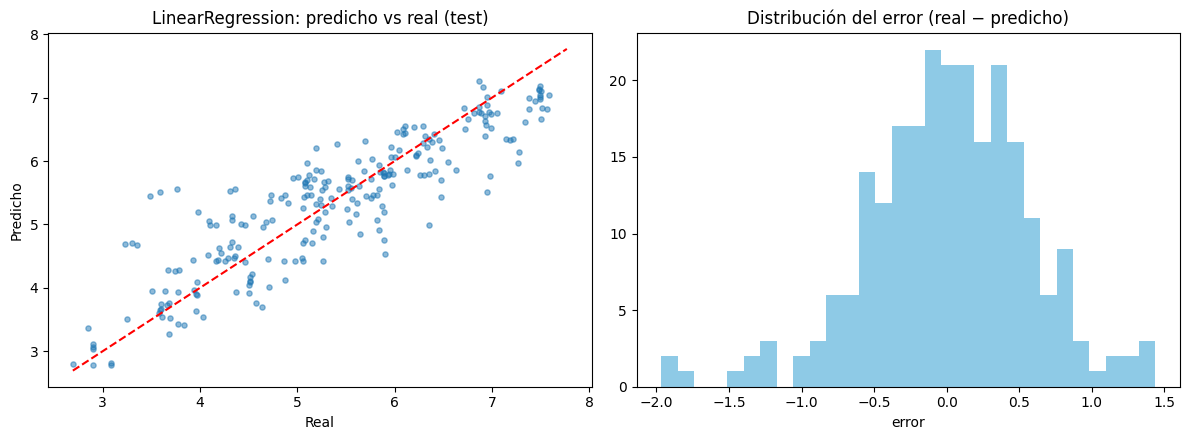

gdp           0.456
freedom       0.242
family        0.237
health        0.204
corruption    0.072
generosity    0.063 
intercepto: 5.386


In [6]:
p = modelo.predict(X_te)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_te, p, alpha=.5, s=14); lim = [y.min(), y.max()]; ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Real'); ax[0].set_ylabel('Predicho'); ax[0].set_title(f'{mejor}: predicho vs real (test)')
ax[1].hist(y_te - p, bins=30, color='#8ecae6'); ax[1].set_title('Distribución del error (real − predicho)'); ax[1].set_xlabel('error')
plt.tight_layout(); plt.show()
if mejor == 'LinearRegression':
    print(pd.Series(modelo.named_steps['model'].coef_, index=cl.FEATURES).round(3).sort_values(ascending=False).to_string(), '\nintercepto:', round(modelo.named_steps['model'].intercept_, 3))

## 4. Serialización: `models/model.pkl` + metadatos

In [7]:
# Reentrenar el pipeline elegido con TODOS los datos no cambia el contrato; aquí se guarda el entrenado con el 70 % para que las métricas reportadas correspondan al artefacto.
(ROOT / 'models').mkdir(exist_ok=True)
joblib.dump(modelo, ROOT / 'models' / 'model.pkl')
meta = {'model': mejor, 'features': cl.FEATURES, 'target': cl.TARGET, 'sklearn_version': sklearn.__version__,
        'split': 'GroupShuffleSplit por country, 70/30, random_state=42',
        'metrics_test': {k: round(float(v), 4) for k, v in test.loc[mejor, ['MAE', 'RMSE', 'R2']].items()}}
(ROOT / 'models' / 'model_metadata.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print(json.dumps(meta, indent=2, ensure_ascii=False))

{
  "model": "LinearRegression",
  "features": [
    "gdp",
    "family",
    "health",
    "freedom",
    "generosity",
    "corruption"
  ],
  "target": "happiness_score",
  "sklearn_version": "1.9.1",
  "split": "GroupShuffleSplit por country, 70/30, random_state=42",
  "metrics_test": {
    "MAE": 0.432,
    "RMSE": 0.562,
    "R2": 0.7837
  }
}


In [8]:
# Verificación: recargar el .pkl y predecir con una fila (mismo orden de columnas)
m2 = joblib.load(ROOT / 'models' / 'model.pkl')
fila = pd.DataFrame([{'gdp': 1.2, 'family': 0.8, 'health': 0.9, 'freedom': 0.6, 'generosity': 0.3, 'corruption': 0.1}])[cl.FEATURES]
print('predicción de ejemplo:', round(float(m2.predict(fila)[0]), 3))

predicción de ejemplo: 6.078
